# Construction Project Analytics & Predictive Modeling

An end-to-end portfolio project demonstrating how construction project data can be transformed into **business insights, statistical analysis, SQL analysis, earned value management, machine learning, forecasting, and dashboard-ready outputs**.

> **Data note:** The dataset is synthetic and intentionally designed to demonstrate realistic construction cost, progress, and schedule patterns. It does not contain confidential client information.

## 1. Project Overview

Construction projects generate large volumes of cost, schedule, quantity, billing, and progress information. A structured analytics workflow can turn these records into actionable information for project controls and management.

This notebook follows one consistent business story:

**Construction domain → Data preparation → Descriptive analytics → Statistical analysis → SQL → EVM → Predictive ML → Forecasting → Dashboard outputs → Project intelligence**

## 1.1 Business Objectives

1. Measure project, contractor, and work-package performance.
2. Identify cost and schedule variances.
3. Apply Earned Value Management (EVM) to quantify project performance.
4. Predict whether a work package is likely to experience high delay in the following month.
5. Forecast next-month actual cost and physical progress.
6. Produce clean analytical datasets suitable for Power BI/Tableau.
7. Demonstrate how predictive outputs can support project-control decisions.

## 1.2 Key Business Questions

- How closely does actual progress track planned progress?
- Which projects, contractors, and work categories show the greatest schedule pressure?
- Where are the largest cost variances?
- What is the relationship between delay, progress variance, and cost variance?
- Which projects have SPI/CPI values below 1.0?
- Can current-month information predict high delay risk next month?
- Can current project information forecast next-month actual cost and progress?
- Which outputs should be surfaced to management in a dashboard?

## 1.3 Analytical Approach

| Stage | Purpose |
|---|---|
| Data generation | Create a reproducible synthetic construction dataset |
| Data understanding | Establish scope, grain, periods, and quality |
| Data preparation | Validate records and derive KPIs |
| EDA | Identify project, contractor, and category patterns |
| Statistical analysis | Quantify relationships and significance |
| SQL analysis | Demonstrate relational querying and aggregation |
| EVM | Integrate cost and schedule performance |
| Delay-risk ML | Predict next-month high delay risk |
| Cost prediction | Forecast next-month actual cost |
| Progress forecasting | Forecast next-month physical progress |
| Dashboard output | Create management-ready datasets |
| Project intelligence | Convert model outputs into decision-support flags |

## 1.4 Notebook Setup

The setup cell is intentionally placed before every analysis step so the notebook can be executed from a **fresh kernel using Run All**.

In [1]:
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)

# Resolve the repository root for both notebook and repository execution contexts.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

VISUALIZATION_DIR = PROJECT_ROOT / "visualizations"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

print("Libraries imported successfully.")
print("Project root:", PROJECT_ROOT)

Libraries imported successfully.
Project root: /Users/ananthrb/Desktop/construction-project-analytics


## 2. Synthetic Dataset Generation

The dataset represents monthly observations at the grain:

**Project × Work Category × Month**

Five projects, ten work categories, and twelve reporting months produce **600 observations**. The generation logic creates realistic variation in progress, cost, and delay while remaining fully reproducible.

In [2]:
project_details = {
    "Healthcare Facility": {"contract_value_cr": 28.50, "contractor": "Contractor A"},
    "Road Development": {"contract_value_cr": 46.75, "contractor": "Contractor B"},
    "Educational Campus": {"contract_value_cr": 18.20, "contractor": "Contractor C"},
    "Food & Commercial Facility": {"contract_value_cr": 9.80, "contractor": "Contractor A"},
    "Administrative Complex": {"contract_value_cr": 35.40, "contractor": "Contractor B"}
}

work_category_weights = {
    "Earthwork": 0.04, "RCC": 0.25, "Masonry": 0.10, "Plastering": 0.07,
    "Flooring": 0.06, "Electrical": 0.15, "Plumbing": 0.07, "HVAC": 0.12,
    "Fire Fighting": 0.05, "Other": 0.09
}

project_performance = {
    "Healthcare Facility": {"progress_factor": 0.94, "cost_factor": 1.04, "delay_factor": 1.10},
    "Road Development": {"progress_factor": 1.02, "cost_factor": 0.98, "delay_factor": 0.80},
    "Educational Campus": {"progress_factor": 1.05, "cost_factor": 0.97, "delay_factor": 0.70},
    "Food & Commercial Facility": {"progress_factor": 0.91, "cost_factor": 1.06, "delay_factor": 1.20},
    "Administrative Complex": {"progress_factor": 0.88, "cost_factor": 1.00, "delay_factor": 1.30}
}

category_cost_factors = {
    "Earthwork": 1.02, "RCC": 1.06, "Masonry": 1.03, "Plastering": 1.01,
    "Flooring": 0.99, "Electrical": 1.05, "Plumbing": 1.04, "HVAC": 1.08,
    "Fire Fighting": 1.02, "Other": 1.00
}

work_profiles = {
    "Earthwork": {"start_month": 1, "duration": 4},
    "RCC": {"start_month": 1, "duration": 8},
    "Masonry": {"start_month": 3, "duration": 7},
    "Plastering": {"start_month": 5, "duration": 6},
    "Flooring": {"start_month": 7, "duration": 5},
    "Electrical": {"start_month": 4, "duration": 8},
    "Plumbing": {"start_month": 4, "duration": 8},
    "HVAC": {"start_month": 7, "duration": 5},
    "Fire Fighting": {"start_month": 6, "duration": 6},
    "Other": {"start_month": 1, "duration": 12}
}

months = pd.date_range("2025-01-01", periods=12, freq="MS")
assert np.isclose(sum(work_category_weights.values()), 1.0)

def calculate_planned_progress(month_number, start_month, duration):
    if month_number < start_month:
        return 0.0
    elapsed_months = month_number - start_month + 1
    return min((elapsed_months / duration) * 100, 100)

np.random.seed(42)
records = []

for project, details in project_details.items():
    contract_value = details["contract_value_cr"]
    contractor = details["contractor"]
    performance = project_performance[project]

    for category, weight in work_category_weights.items():
        category_budget = contract_value * weight
        start_month = work_profiles[category]["start_month"]
        duration = work_profiles[category]["duration"]
        previous_actual_progress = 0.0

        for month_number, month in enumerate(months, start=1):
            planned_progress = calculate_planned_progress(month_number, start_month, duration)
            progress_noise = np.random.normal(0, 3)
            actual_progress = np.clip(
                planned_progress * performance["progress_factor"] + progress_noise, 0, 100
            )
            if planned_progress == 0:
                actual_progress = 0
            actual_progress = min(max(previous_actual_progress, actual_progress), 100)
            previous_actual_progress = actual_progress

            planned_cost = category_budget * planned_progress / 100
            cost_noise = np.random.normal(0, 0.02)
            actual_cost = max(
                planned_cost * performance["cost_factor"] * category_cost_factors[category] * (1 + cost_noise),
                0
            )

            delay_days = max(0, int(np.random.normal(5 * performance["delay_factor"], 3)))

            records.append({
                "project_name": project,
                "contractor": contractor,
                "month": month,
                "work_category": category,
                "contract_value_cr": contract_value,
                "budget_cr": category_budget,
                "planned_progress_pct": planned_progress,
                "actual_progress_pct": actual_progress,
                "planned_cost_cr": planned_cost,
                "actual_cost_cr": actual_cost,
                "delay_days": delay_days
            })

df = pd.DataFrame(records)
print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns)}")
print("Projects:", df["project_name"].nunique())
print("Work categories:", df["work_category"].nunique())
print("Reporting months:", df["month"].nunique())

Rows: 600
Columns: 11
Projects: 5
Work categories: 10
Reporting months: 12


## 3. Data Understanding & Quality Checks

Before modelling, establish the dataset's structure and validate its grain. These checks prevent downstream analytical errors such as duplicate counting, incorrect chronology, or invalid numeric values.

In [3]:
print("Shape:", df.shape)
print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nDate range:", df["month"].min().date(), "to", df["month"].max().date())
print("\nMissing values:")
display(df.isna().sum().to_frame("missing").query("missing > 0"))

Shape: (600, 11)

Data types:


,dtype
project_name,str
contractor,str
month,datetime64[us]
work_category,str
contract_value_cr,float64
budget_cr,float64
planned_progress_pct,float64
actual_progress_pct,float64
planned_cost_cr,float64
actual_cost_cr,float64



Date range: 2025-01-01 to 2025-12-01

Missing values:


,missing


In [4]:
duplicate_rows = df.duplicated().sum()
duplicate_grain = df.duplicated(
    subset=["project_name", "work_category", "month"]
).sum()

print("Duplicate rows:", duplicate_rows)
print("Duplicate project-work-category-month records:", duplicate_grain)

assert duplicate_rows == 0
assert duplicate_grain == 0
assert (df["planned_progress_pct"] >= 0).all() and (df["planned_progress_pct"] <= 100).all()
assert (df["actual_progress_pct"] >= 0).all() and (df["actual_progress_pct"] <= 100).all()
assert (df["planned_cost_cr"] >= 0).all() and (df["actual_cost_cr"] >= 0).all()
assert (df["delay_days"] >= 0).all()

progress_change = (
    df.sort_values(["project_name", "work_category", "month"])
      .groupby(["project_name", "work_category"])["actual_progress_pct"]
      .diff()
)
print("Negative cumulative-progress changes:", (progress_change < 0).sum())

Duplicate rows: 0
Duplicate project-work-category-month records: 0
Negative cumulative-progress changes: 0


### Data Quality Conclusion

The dataset has one row per **project × work category × month**, contains no duplicate grain records, and satisfies the basic numeric and cumulative-progress validation rules. This provides a controlled foundation for the downstream analytics.

## 4. Data Preparation & Construction KPIs

The following variables translate raw project records into common project-controls measures. Variances are expressed so that negative progress variance indicates schedule underperformance and positive cost variance indicates cost pressure.

In [5]:
df["progress_variance_pct"] = (
    df["actual_progress_pct"] - df["planned_progress_pct"]
)

df["cost_variance_cr"] = (
    df["actual_cost_cr"] - df["planned_cost_cr"]
)

df["cost_variance_pct"] = np.where(
    df["planned_cost_cr"] > 0,
    df["cost_variance_cr"] / df["planned_cost_cr"] * 100,
    np.nan
)

df["financial_progress_pct"] = np.where(
    df["budget_cr"] > 0,
    df["actual_cost_cr"] / df["budget_cr"] * 100,
    np.nan
)

df["physical_financial_gap_pct"] = (
    df["actual_progress_pct"] - df["financial_progress_pct"]
)

df["schedule_status"] = np.select(
    [df["progress_variance_pct"] < -5, df["progress_variance_pct"] > 5],
    ["Behind Plan", "Ahead of Plan"],
    default="On / Near Plan"
)

df["month_number"] = df["month"].dt.month

# Row-level EVM metrics are retained for predictive feature engineering.
df["PV_cr"] = df["planned_cost_cr"]
df["EV_cr"] = df["budget_cr"] * df["actual_progress_pct"] / 100
df["AC_cr"] = df["actual_cost_cr"]
df["SPI"] = np.where(df["PV_cr"] > 0, df["EV_cr"] / df["PV_cr"], np.nan)
df["CPI"] = np.where(df["AC_cr"] > 0, df["EV_cr"] / df["AC_cr"], np.nan)

print("Derived KPI columns created:")
print([c for c in df.columns if c not in ["project_name", "contractor", "month", "work_category"]])

Derived KPI columns created:
['contract_value_cr', 'budget_cr', 'planned_progress_pct', 'actual_progress_pct', 'planned_cost_cr', 'actual_cost_cr', 'delay_days', 'progress_variance_pct', 'cost_variance_cr', 'cost_variance_pct', 'financial_progress_pct', 'physical_financial_gap_pct', 'schedule_status', 'month_number', 'PV_cr', 'EV_cr', 'AC_cr', 'SPI', 'CPI']


## 5. Exploratory Data Analysis

### 5.1 Project Performance

Project-level aggregation is used for management interpretation rather than relying on individual work-package rows.

In [6]:
project_summary = (
    df.groupby(["project_name", "contractor"], as_index=False)
      .agg(
          contract_value_cr=("contract_value_cr", "first"),
          avg_planned_progress_pct=("planned_progress_pct", "mean"),
          avg_actual_progress_pct=("actual_progress_pct", "mean"),
          avg_progress_variance_pct=("progress_variance_pct", "mean"),
          total_actual_cost_cr=("actual_cost_cr", "sum"),
          total_planned_cost_cr=("planned_cost_cr", "sum"),
          avg_delay_days=("delay_days", "mean"),
          max_delay_days=("delay_days", "max")
      )
)
project_summary["cost_variance_cr"] = (
    project_summary["total_actual_cost_cr"] - project_summary["total_planned_cost_cr"]
)
project_summary["cost_variance_pct"] = np.where(
    project_summary["total_planned_cost_cr"] > 0,
    project_summary["cost_variance_cr"] / project_summary["total_planned_cost_cr"] * 100,
    np.nan
)
display(project_summary.sort_values("avg_progress_variance_pct"))

,project_name,contractor,contract_value_cr,avg_planned_progress_pct,avg_actual_progress_pct,avg_progress_variance_pct,total_actual_cost_cr,total_planned_cost_cr,avg_delay_days,max_delay_days,cost_variance_cr,cost_variance_pct
0,Administrative Complex,Contractor B,35.40,51.25,46.00,-5.25,234.93,225.50,6.17,14,9.44,4.18
2,Food & Commercial Facility,Contractor A,9.80,51.25,47.53,-3.72,68.97,62.43,5.67,12,6.54,10.48
3,Healthcare Facility,Contractor A,28.50,51.25,48.73,-2.52,195.98,181.54,5.40,17,14.44,7.95
4,Road Development,Contractor B,46.75,51.25,51.54,0.29,303.20,297.80,3.73,11,5.40,1.81
1,Educational Campus,Contractor C,18.20,51.25,52.76,1.51,117.58,115.93,3.44,11,1.64,1.42


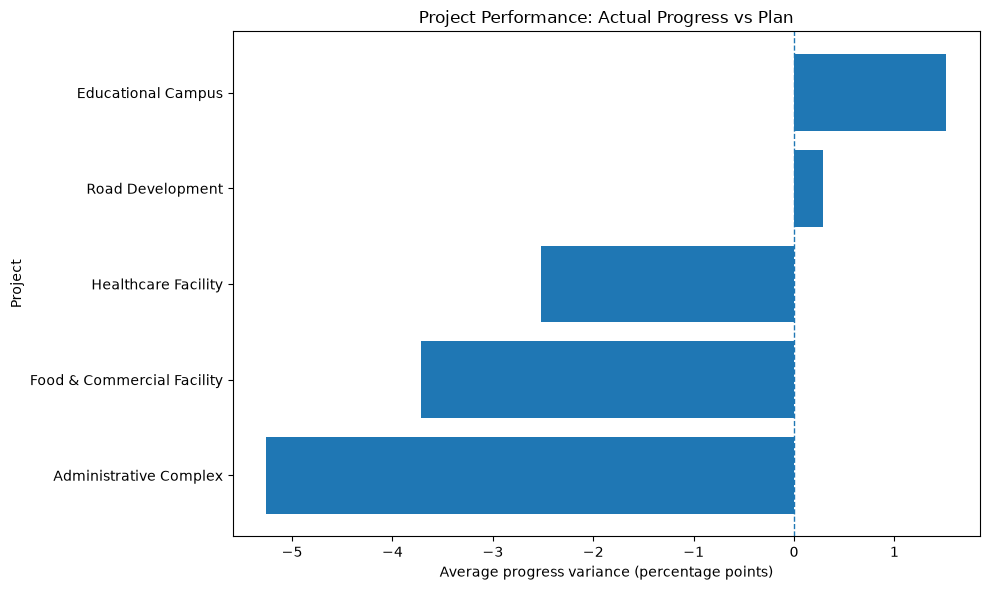

In [7]:
project_plot = project_summary.sort_values("avg_progress_variance_pct")

plt.figure(figsize=(10, 6))
plt.barh(project_plot["project_name"], project_plot["avg_progress_variance_pct"])
plt.axvline(0, linestyle="--", linewidth=1)
plt.xlabel("Average progress variance (percentage points)")
plt.ylabel("Project")
plt.title("Project Performance: Actual Progress vs Plan")
plt.tight_layout()
plt.savefig(VISUALIZATION_DIR / "01_project_progress_variance.png", dpi=300, bbox_inches="tight")
plt.show()

### 5.1.1 Project Performance Visualization

This chart answers the management question: **Which projects are performing below their planned progress?** Negative values indicate that actual progress is behind plan.

### 5.2 Work-Category Performance

In [8]:
category_summary = (
    df.groupby("work_category", as_index=False)
      .agg(
          avg_delay_days=("delay_days", "mean"),
          max_delay_days=("delay_days", "max"),
          avg_progress_variance_pct=("progress_variance_pct", "mean"),
          avg_cost_variance_pct=("cost_variance_pct", "mean")
      )
      .sort_values("avg_delay_days", ascending=False)
)
display(category_summary)

,work_category,avg_delay_days,max_delay_days,avg_progress_variance_pct,avg_cost_variance_pct
9,RCC,5.27,12,-2.70,7.20
3,Flooring,5.17,13,-1.60,-0.00
2,Fire Fighting,5.15,12,-0.86,3.17
7,Plastering,4.98,12,-1.79,1.46
1,Electrical,4.87,17,-1.50,6.43
4,HVAC,4.75,11,-1.22,8.21
0,Earthwork,4.73,11,-3.15,3.09
6,Other,4.72,13,-2.52,1.08
8,Plumbing,4.65,10,-1.51,4.96
5,Masonry,4.53,12,-2.51,3.97


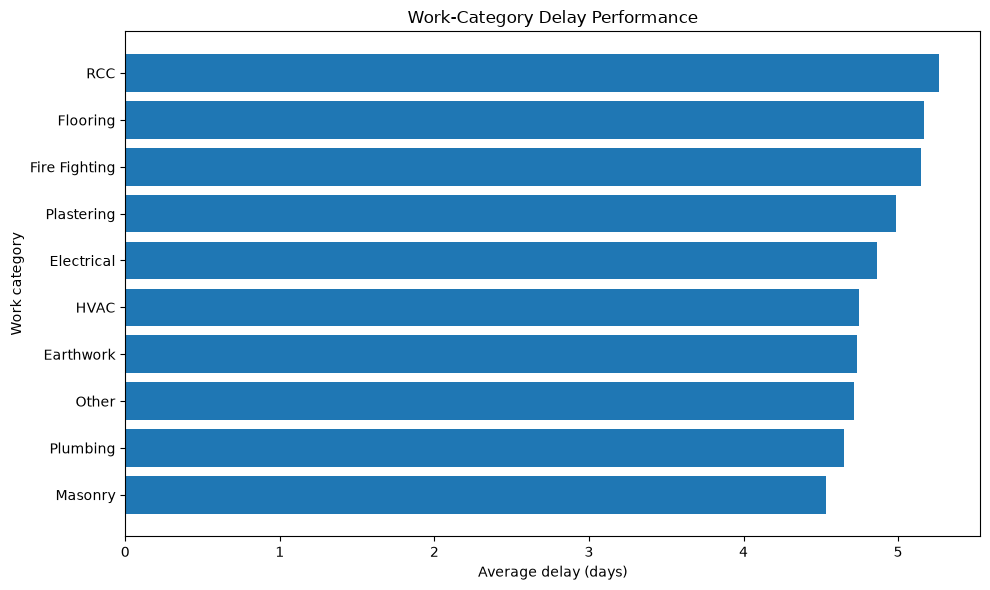

In [9]:
category_plot = category_summary.sort_values("avg_delay_days", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(category_plot["work_category"], category_plot["avg_delay_days"])
plt.xlabel("Average delay (days)")
plt.ylabel("Work category")
plt.title("Work-Category Delay Performance")
plt.tight_layout()
plt.savefig(VISUALIZATION_DIR / "12_category_average_delay.png", dpi=300, bbox_inches="tight")
plt.show()

### 5.3 Contractor Performance

In [10]:
contractor_summary = (
    df.groupby("contractor", as_index=False)
      .agg(
          avg_progress_variance_pct=("progress_variance_pct", "mean"),
          avg_cost_variance_pct=("cost_variance_pct", "mean"),
          avg_delay_days=("delay_days", "mean"),
          total_actual_cost_cr=("actual_cost_cr", "sum")
      )
      .sort_values("avg_progress_variance_pct")
)
display(contractor_summary)

,contractor,avg_progress_variance_pct,avg_cost_variance_pct,avg_delay_days,total_actual_cost_cr
0,Contractor A,-3.12,7.90,5.53,264.95
1,Contractor B,-2.48,1.87,4.95,538.13
2,Contractor C,1.51,0.34,3.44,117.58


## 6. Statistical Analysis

Correlation analysis is used to quantify relationships among delay, progress variance, and cost variance. Because the data are observational and repeated by project/work package, these results are interpreted as **associations**, not causal effects.

### 5.3.1 Contractor Performance Visualization

This comparison highlights differences in average progress performance across contractors. It is intended for performance monitoring, not causal attribution.

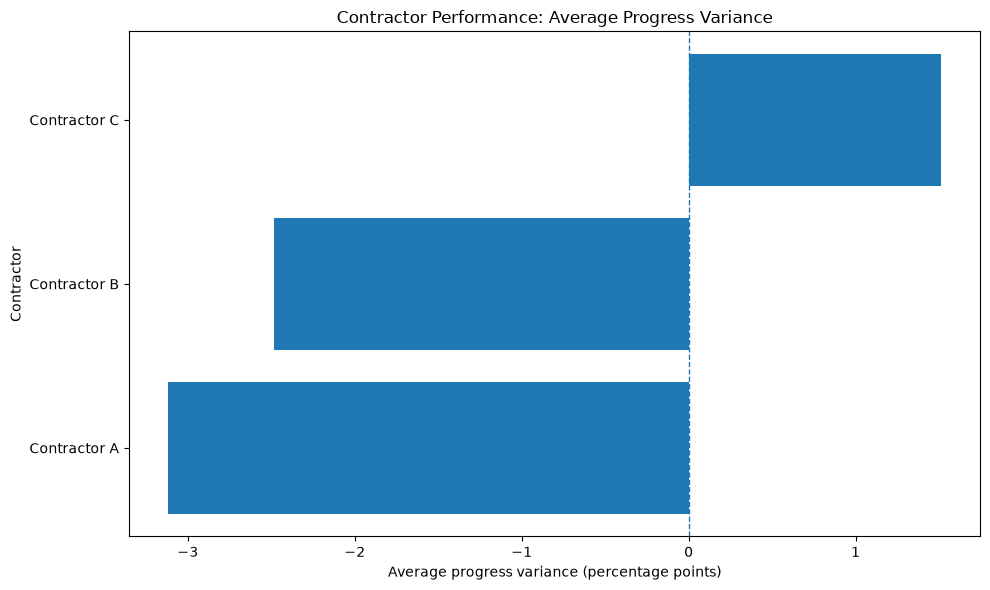

In [11]:
contractor_plot = contractor_summary.sort_values("avg_progress_variance_pct")

plt.figure(figsize=(10, 6))
plt.barh(contractor_plot["contractor"], contractor_plot["avg_progress_variance_pct"])
plt.axvline(0, linestyle="--", linewidth=1)
plt.xlabel("Average progress variance (percentage points)")
plt.ylabel("Contractor")
plt.title("Contractor Performance: Average Progress Variance")
plt.tight_layout()
plt.savefig(VISUALIZATION_DIR / "02_contractor_progress_variance.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
analysis_columns = [
    "delay_days",
    "progress_variance_pct",
    "cost_variance_pct",
    "actual_progress_pct",
    "actual_cost_cr"
]
correlation_matrix = df[analysis_columns].corr(method="spearman")
display(correlation_matrix)

,delay_days,progress_variance_pct,cost_variance_pct,actual_progress_pct,actual_cost_cr
delay_days,1.00,-0.23,0.23,-0.02,0.01
progress_variance_pct,-0.23,1.00,-0.38,-0.27,-0.30
cost_variance_pct,0.23,-0.38,1.00,-0.06,0.01
actual_progress_pct,-0.02,-0.27,-0.06,1.00,0.79
actual_cost_cr,0.01,-0.30,0.01,0.79,1.00


In [13]:
rho, p_value = stats.spearmanr(
    df["delay_days"],
    df["progress_variance_pct"],
    nan_policy="omit"
)
print(f"Spearman correlation between delay and progress variance: {rho:.3f}")
print(f"p-value: {p_value:.4g}")

if p_value < 0.05:
    print("The association is statistically significant at the 5% level.")
else:
    print("The association is not statistically significant at the 5% level.")

Spearman correlation between delay and progress variance: -0.227
p-value: 1.826e-08
The association is statistically significant at the 5% level.


### 6.1 Correlation Visualization

The Spearman correlation matrix summarizes monotonic associations among selected project-control variables. Correlation does not establish causation.

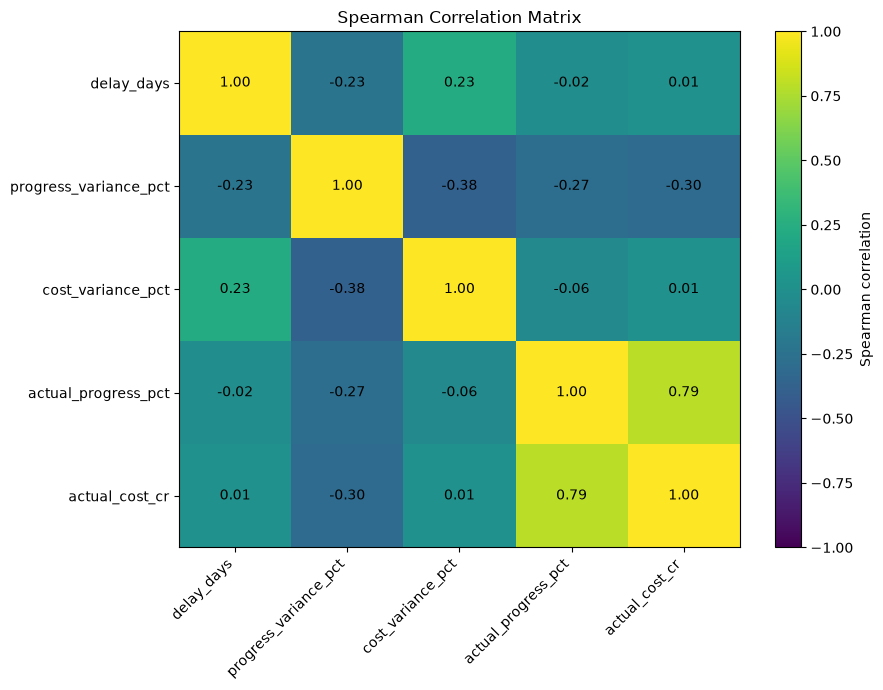

In [14]:
plt.figure(figsize=(9, 7))
plt.imshow(correlation_matrix, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Spearman correlation")
plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=45, ha="right")
plt.yticks(range(len(correlation_matrix.index)), correlation_matrix.index)
for row in range(correlation_matrix.shape[0]):
    for col in range(correlation_matrix.shape[1]):
        value = correlation_matrix.iloc[row, col]
        plt.text(col, row, f"{value:.2f}", ha="center", va="center")
plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.savefig(VISUALIZATION_DIR / "03_correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. SQL Analysis

The same business questions are expressed using SQL against an in-memory SQLite database. This demonstrates the ability to move between pandas-based analysis and relational querying.

In [15]:
connection = sqlite3.connect(":memory:")
df.to_sql("project_data", connection, index=False, if_exists="replace")

project_sql = pd.read_sql_query("""
    SELECT
        project_name,
        contractor,
        ROUND(AVG(progress_variance_pct), 2) AS avg_progress_variance_pct,
        ROUND(AVG(cost_variance_pct), 2) AS avg_cost_variance_pct,
        ROUND(AVG(delay_days), 2) AS avg_delay_days
    FROM project_data
    GROUP BY project_name, contractor
    ORDER BY avg_progress_variance_pct ASC;
""", connection)

display(project_sql)

,project_name,contractor,avg_progress_variance_pct,avg_cost_variance_pct,avg_delay_days
0,Administrative Complex,Contractor B,-5.25,3.02,6.17
1,Food & Commercial Facility,Contractor A,-3.72,9.24,5.67
2,Healthcare Facility,Contractor A,-2.52,6.55,5.40
3,Road Development,Contractor B,0.29,0.72,3.73
4,Educational Campus,Contractor C,1.51,0.34,3.44


In [16]:
category_sql = pd.read_sql_query("""
    SELECT
        work_category,
        ROUND(AVG(delay_days), 2) AS avg_delay_days,
        ROUND(AVG(cost_variance_pct), 2) AS avg_cost_variance_pct,
        ROUND(AVG(progress_variance_pct), 2) AS avg_progress_variance_pct
    FROM project_data
    GROUP BY work_category
    ORDER BY avg_delay_days DESC;
""", connection)

display(category_sql)

,work_category,avg_delay_days,avg_cost_variance_pct,avg_progress_variance_pct
0,RCC,5.27,7.20,-2.70
1,Flooring,5.17,-0.00,-1.60
2,Fire Fighting,5.15,3.17,-0.86
3,Plastering,4.98,1.46,-1.79
4,Electrical,4.87,6.43,-1.50
5,HVAC,4.75,8.21,-1.22
6,Earthwork,4.73,3.09,-3.15
7,Other,4.72,1.08,-2.52
8,Plumbing,4.65,4.96,-1.51
9,Masonry,4.53,3.97,-2.51


In [17]:
sql_delay_threshold = float(
    df["delay_days"].mean()
    + 1.5 * (df["delay_days"] - df["delay_days"].mean()).abs().mean()
)

high_risk_sql = pd.read_sql_query("""
    SELECT
        project_name,
        work_category,
        month,
        delay_days,
        progress_variance_pct,
        cost_variance_pct
    FROM project_data
    WHERE delay_days >= ?
    ORDER BY delay_days DESC;
""", connection, params=(sql_delay_threshold,))

display(high_risk_sql.head(10))
connection.close()


,project_name,work_category,month,delay_days,progress_variance_pct,cost_variance_pct
0,Healthcare Facility,Electrical,2025-10-01 00:00:00,17,-3.71,10.32
1,Administrative Complex,Electrical,2025-10-01 00:00:00,14,-7.54,7.49
2,Healthcare Facility,Flooring,2025-12-01 00:00:00,13,-1.64,2.42
3,Administrative Complex,Other,2025-01-01 00:00:00,13,-1.74,-1.69
4,Healthcare Facility,Plastering,2025-02-01 00:00:00,12,0.00,NaN
5,Healthcare Facility,Plastering,2025-06-01 00:00:00,12,-6.21,6.27
6,Food & Commercial Facility,Masonry,2025-02-01 00:00:00,12,0.00,NaN
7,Food & Commercial Facility,Flooring,2025-02-01 00:00:00,12,0.00,NaN
8,Food & Commercial Facility,Fire Fighting,2025-05-01 00:00:00,12,0.00,NaN
9,Administrative Complex,RCC,2025-07-01 00:00:00,12,-5.87,10.25


## 8. Earned Value Management (EVM)

EVM combines schedule and cost information using:

- **PV (Planned Value):** budgeted value of work planned to be completed.
- **EV (Earned Value):** budgeted value of work actually completed.
- **AC (Actual Cost):** actual expenditure for completed work.
- **SPI = EV / PV:** schedule efficiency; below 1.0 indicates behind plan.
- **CPI = EV / AC:** cost efficiency; below 1.0 indicates cost inefficiency.

Ratios are calculated **after project-month aggregation**, which is preferable to averaging row-level ratios.

In [18]:
project_month_evm = (
    df.groupby(["project_name", "contractor", "month"], as_index=False)
      .agg(
          PV_cr=("planned_cost_cr", "sum"),
          EV_cr=("budget_cr", lambda x: 0),
          AC_cr=("actual_cost_cr", "sum")
      )
)

# EV must use the budget-weighted physical progress of the work packages.
earned_value = (
    df.assign(EV_component=df["budget_cr"] * df["actual_progress_pct"] / 100)
      .groupby(["project_name", "contractor", "month"], as_index=False)["EV_component"]
      .sum()
      .rename(columns={"EV_component": "EV_cr"})
)

project_month_evm = project_month_evm.drop(columns="EV_cr").merge(
    earned_value,
    on=["project_name", "contractor", "month"],
    how="left"
)

project_month_evm["SV_cr"] = project_month_evm["EV_cr"] - project_month_evm["PV_cr"]
project_month_evm["CV_cr"] = project_month_evm["EV_cr"] - project_month_evm["AC_cr"]
project_month_evm["SPI"] = np.where(
    project_month_evm["PV_cr"] > 0,
    project_month_evm["EV_cr"] / project_month_evm["PV_cr"],
    np.nan
)
project_month_evm["CPI"] = np.where(
    project_month_evm["AC_cr"] > 0,
    project_month_evm["EV_cr"] / project_month_evm["AC_cr"],
    np.nan
)

display(project_month_evm.head(10))

,project_name,contractor,month,PV_cr,AC_cr,EV_cr,SV_cr,CV_cr,SPI,CPI
0,Administrative Complex,Contractor B,2025-01-01,1.73,1.81,1.49,-0.23,-0.32,0.86,0.82
1,Administrative Complex,Contractor B,2025-02-01,3.45,3.64,2.85,-0.60,-0.79,0.83,0.78
2,Administrative Complex,Contractor B,2025-03-01,5.68,5.95,5.33,-0.35,-0.62,0.94,0.90
3,Administrative Complex,Contractor B,2025-04-01,8.89,9.11,8.28,-0.60,-0.83,0.93,0.91
4,Administrative Complex,Contractor B,2025-05-01,12.15,12.94,10.16,-1.99,-2.78,0.84,0.79
5,Administrative Complex,Contractor B,2025-06-01,15.71,16.19,14.65,-1.06,-1.54,0.93,0.91
6,Administrative Complex,Contractor B,2025-07-01,20.54,21.61,19.02,-1.52,-2.59,0.93,0.88
7,Administrative Complex,Contractor B,2025-08-01,25.38,26.55,22.95,-2.43,-3.60,0.90,0.86
8,Administrative Complex,Contractor B,2025-09-01,29.10,30.16,25.98,-3.12,-4.17,0.89,0.86
9,Administrative Complex,Contractor B,2025-10-01,32.33,33.59,28.98,-3.34,-4.60,0.90,0.86


In [19]:
evm_project_summary = (
    project_month_evm.groupby(["project_name", "contractor"], as_index=False)
      .agg(
          total_PV_cr=("PV_cr", "sum"),
          total_EV_cr=("EV_cr", "sum"),
          total_AC_cr=("AC_cr", "sum"),
          avg_SPI=("SPI", "mean"),
          avg_CPI=("CPI", "mean")
      )
)
evm_project_summary["total_SV_cr"] = evm_project_summary["total_EV_cr"] - evm_project_summary["total_PV_cr"]
evm_project_summary["total_CV_cr"] = evm_project_summary["total_EV_cr"] - evm_project_summary["total_AC_cr"]

display(evm_project_summary.sort_values("avg_SPI"))

,project_name,contractor,total_PV_cr,total_EV_cr,total_AC_cr,avg_SPI,avg_CPI,total_SV_cr,total_CV_cr
0,Administrative Complex,Contractor B,225.50,203.49,234.93,0.90,0.86,-22.01,-31.45
3,Healthcare Facility,Contractor A,181.55,171.81,195.98,0.95,0.88,-9.74,-24.18
2,Food & Commercial Facility,Contractor A,62.43,57.62,68.97,0.97,0.88,-4.80,-11.35
4,Road Development,Contractor B,297.80,299.76,303.20,0.99,0.97,1.96,-3.44
1,Educational Campus,Contractor C,115.93,119.56,117.58,1.05,1.04,3.62,1.98


## 9. Project 1 — Next-Month Delay Risk Prediction

### Business problem

Project controls teams need an early-warning mechanism for work packages that may experience unusually high delay in the **following month**.

**Prediction unit:** current month, project, and work category.  
**Target:** next month's delay days.  
**Classification target:** high delay risk = next-month delay above the 75th percentile of the **training target distribution**.

Using the training distribution to define the threshold prevents information from the test period from influencing target construction.

### 8.1 EVM Trend Visualization

EVM is most useful as a time series. This chart compares **Planned Value (PV), Earned Value (EV), and Actual Cost (AC)** for the portfolio over the reporting period.

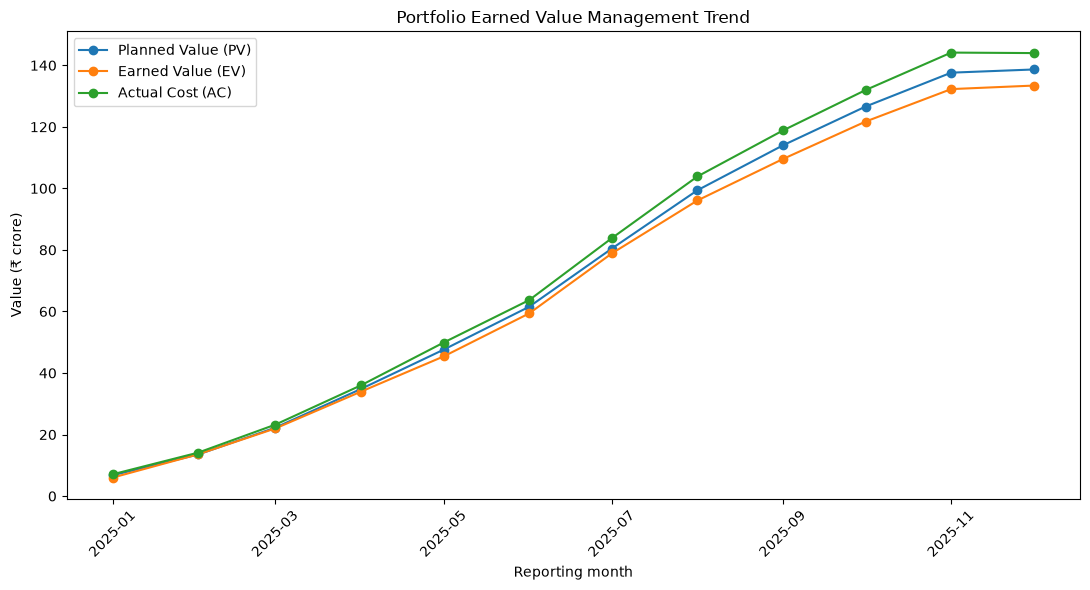

In [20]:
evm_trend = (
    project_month_evm.groupby("month", as_index=False)[["PV_cr", "EV_cr", "AC_cr"]]
    .sum().sort_values("month")
)

plt.figure(figsize=(11, 6))
plt.plot(evm_trend["month"], evm_trend["PV_cr"], marker="o", label="Planned Value (PV)")
plt.plot(evm_trend["month"], evm_trend["EV_cr"], marker="o", label="Earned Value (EV)")
plt.plot(evm_trend["month"], evm_trend["AC_cr"], marker="o", label="Actual Cost (AC)")
plt.xlabel("Reporting month")
plt.ylabel("Value (₹ crore)")
plt.title("Portfolio Earned Value Management Trend")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(VISUALIZATION_DIR / "04_evm_pv_ev_ac_trend.png", dpi=300, bbox_inches="tight")
plt.show()

In [21]:
delay_model_df = df.copy()
group_columns = ["project_name", "work_category"]
delay_model_df = delay_model_df.sort_values(group_columns + ["month"]).reset_index(drop=True)

delay_model_df["next_month_delay_days"] = (
    delay_model_df.groupby(group_columns)["delay_days"].shift(-1)
)

delay_model_df = delay_model_df.dropna(subset=["next_month_delay_days"]).copy()

train_cutoff = pd.Timestamp("2025-09-01")
train_delay = delay_model_df[delay_model_df["month"] < train_cutoff].copy()
test_delay = delay_model_df[delay_model_df["month"] >= train_cutoff].copy()

delay_threshold = train_delay["next_month_delay_days"].quantile(0.75)
train_delay["high_delay_risk"] = (train_delay["next_month_delay_days"] > delay_threshold).astype(int)
test_delay["high_delay_risk"] = (test_delay["next_month_delay_days"] > delay_threshold).astype(int)

print(f"Training rows: {len(train_delay)}")
print(f"Testing rows: {len(test_delay)}")
print(f"Training-derived high-delay threshold: {delay_threshold:.1f} days")
print("\nTraining class distribution:")
print(train_delay["high_delay_risk"].value_counts().sort_index())
print("\nTesting class distribution:")
print(test_delay["high_delay_risk"].value_counts().sort_index())

Training rows: 400
Testing rows: 150
Training-derived high-delay threshold: 7.0 days

Training class distribution:
high_delay_risk
0    325
1     75
Name: count, dtype: int64

Testing class distribution:
high_delay_risk
0    115
1     35
Name: count, dtype: int64


### 9.1 Predictive Features

Features are limited to information available at the current reporting month. Lagged variables use only prior months. The next-month outcome is never used as an input feature.

In [22]:
def add_delay_features(data):
    result = data.copy().sort_values(group_columns + ["month"]).reset_index(drop=True)
    for column in ["delay_days", "progress_variance_pct", "cost_variance_pct", "SPI", "CPI", "actual_cost_cr"]:
        result[f"{column}_lag1"] = result.groupby(group_columns)[column].shift(1)

    result["delay_rolling_3m"] = (
        result.groupby(group_columns)["delay_days"]
        .transform(lambda values: values.shift(1).rolling(3, min_periods=1).mean())
    )
    result["progress_variance_rolling_3m"] = (
        result.groupby(group_columns)["progress_variance_pct"]
        .transform(lambda values: values.shift(1).rolling(3, min_periods=1).mean())
    )
    result["delay_change"] = result["delay_days"] - result["delay_days_lag1"]
    result["progress_variance_change"] = result["progress_variance_pct"] - result["progress_variance_pct_lag1"]
    result["cost_variance_change"] = result["cost_variance_pct"] - result["cost_variance_pct_lag1"]
    return result

delay_model_df = add_delay_features(df)
delay_model_df["next_month_delay_days"] = (
    delay_model_df.groupby(group_columns)["delay_days"].shift(-1)
)
delay_model_df = delay_model_df.dropna(subset=["next_month_delay_days"]).copy()

train_delay = delay_model_df[delay_model_df["month"] < train_cutoff].copy()
test_delay = delay_model_df[delay_model_df["month"] >= train_cutoff].copy()
delay_threshold = train_delay["next_month_delay_days"].quantile(0.75)
train_delay["high_delay_risk"] = (train_delay["next_month_delay_days"] > delay_threshold).astype(int)
test_delay["high_delay_risk"] = (test_delay["next_month_delay_days"] > delay_threshold).astype(int)

current_features = [
    "contract_value_cr", "budget_cr", "planned_progress_pct", "actual_progress_pct",
    "planned_cost_cr", "actual_cost_cr", "delay_days", "progress_variance_pct",
    "cost_variance_cr", "cost_variance_pct", "financial_progress_pct",
    "physical_financial_gap_pct", "SPI", "CPI", "month_number",
    "delay_days_lag1", "progress_variance_pct_lag1", "cost_variance_pct_lag1",
    "SPI_lag1", "CPI_lag1", "actual_cost_cr_lag1", "delay_rolling_3m",
    "progress_variance_rolling_3m", "delay_change", "progress_variance_change",
    "cost_variance_change"
]
categorical_features = ["project_name", "contractor", "work_category"]
feature_columns = categorical_features + current_features

X_train_delay = train_delay[feature_columns]
y_train_delay = train_delay["high_delay_risk"]
X_test_delay = test_delay[feature_columns]
y_test_delay = test_delay["high_delay_risk"]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

delay_preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, current_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Training feature shape:", X_train_delay.shape)
print("Testing feature shape:", X_test_delay.shape)

Training feature shape: (400, 29)
Testing feature shape: (150, 29)


In [23]:
delay_models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", delay_preprocessor),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", delay_preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=300, max_depth=6, min_samples_leaf=5,
            class_weight="balanced", random_state=42, n_jobs=-1
        ))
    ]),
    "Gradient Boosting": Pipeline([
        ("preprocessor", delay_preprocessor),
        ("model", GradientBoostingClassifier(
            n_estimators=200, learning_rate=0.05, max_depth=3,
            min_samples_leaf=5, random_state=42
        ))
    ])
}

delay_results = []
delay_predictions = {}

for name, model in delay_models.items():
    model.fit(X_train_delay, y_train_delay)
    predictions = model.predict(X_test_delay)
    probabilities = model.predict_proba(X_test_delay)[:, 1]
    delay_predictions[name] = (predictions, probabilities)

    delay_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_delay, predictions),
        "Precision": precision_score(y_test_delay, predictions, zero_division=0),
        "Recall": recall_score(y_test_delay, predictions, zero_division=0),
        "F1": f1_score(y_test_delay, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test_delay, probabilities),
        "PR-AUC": average_precision_score(y_test_delay, probabilities)
    })

delay_model_comparison = pd.DataFrame(delay_results).sort_values("ROC-AUC", ascending=False)
display(delay_model_comparison.round(3))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
1,Random Forest,0.69,0.36,0.46,0.41,0.64,0.34
2,Gradient Boosting,0.77,0.56,0.14,0.23,0.57,0.31
0,Logistic Regression,0.61,0.23,0.29,0.26,0.56,0.26


In [24]:
best_delay_model_name = delay_model_comparison.iloc[0]["Model"]
best_delay_model = delay_models[best_delay_model_name]
best_delay_predictions, best_delay_probabilities = delay_predictions[best_delay_model_name]

print("Selected model:", best_delay_model_name)
print("\nClassification report:")
print(classification_report(y_test_delay, best_delay_predictions, digits=3, zero_division=0))

print("ROC-AUC:", round(roc_auc_score(y_test_delay, best_delay_probabilities), 3))
print("PR-AUC:", round(average_precision_score(y_test_delay, best_delay_probabilities), 3))

Selected model: Random Forest

Classification report:
              precision    recall  f1-score   support

           0      0.821     0.757     0.787       115
           1      0.364     0.457     0.405        35

    accuracy                          0.687       150
   macro avg      0.592     0.607     0.596       150
weighted avg      0.714     0.687     0.698       150

ROC-AUC: 0.639
PR-AUC: 0.342


### 9.3 Delay-Risk Model Comparison

The model comparison emphasizes discrimination and minority-class performance. ROC-AUC and PR-AUC are shown alongside F1 so the selection is not driven by accuracy alone.

### 9.4 Best Delay Model: ROC and Precision–Recall Curves

These curves show how the selected model separates high-risk from low-risk observations across probability thresholds.

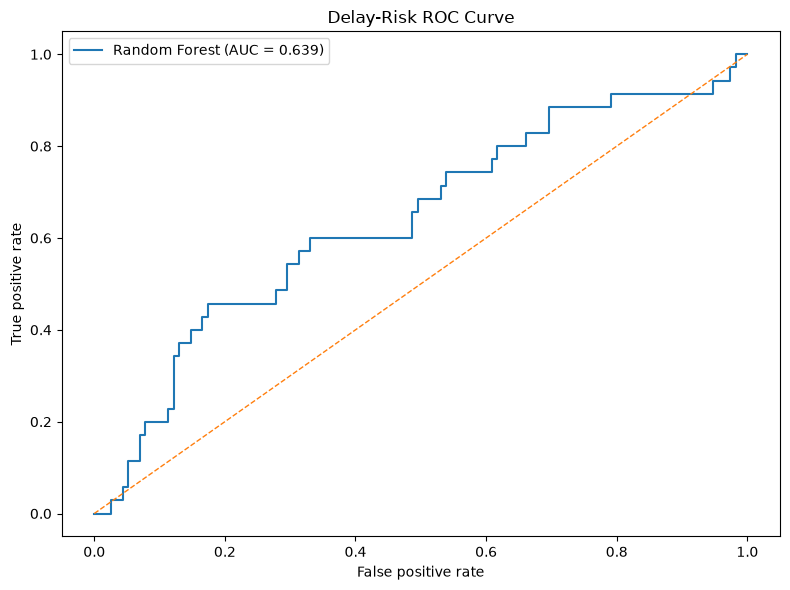

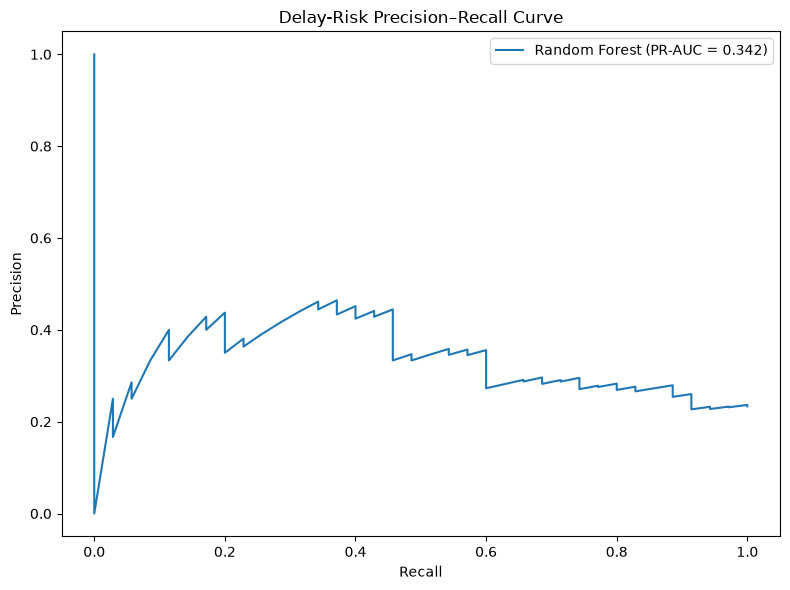

In [25]:
from sklearn.metrics import roc_curve, precision_recall_curve

fpr, tpr, _ = roc_curve(y_test_delay, best_delay_probabilities)
precision_values, recall_values, _ = precision_recall_curve(y_test_delay, best_delay_probabilities)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"{best_delay_model_name} (AUC = {roc_auc_score(y_test_delay, best_delay_probabilities):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Delay-Risk ROC Curve")
plt.legend()
plt.tight_layout()
plt.savefig(VISUALIZATION_DIR / "06_delay_risk_roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 6))
plt.plot(recall_values, precision_values, label=f"{best_delay_model_name} (PR-AUC = {average_precision_score(y_test_delay, best_delay_probabilities):.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Delay-Risk Precision–Recall Curve")
plt.legend()
plt.tight_layout()
plt.savefig(VISUALIZATION_DIR / "07_delay_risk_pr_curve.png", dpi=300, bbox_inches="tight")
plt.show()

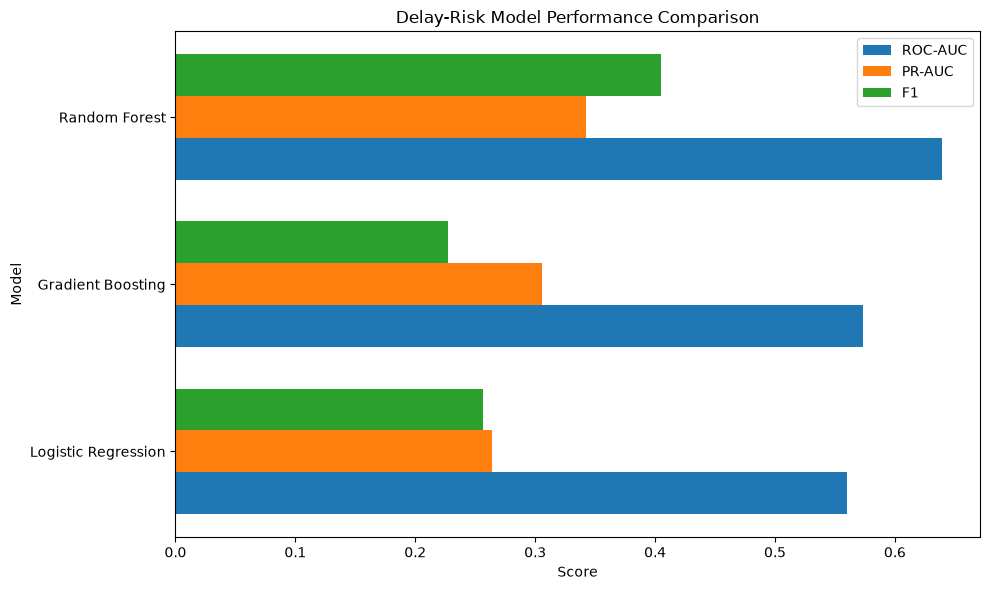

In [26]:
delay_plot = delay_model_comparison.sort_values("ROC-AUC", ascending=True)
y = np.arange(len(delay_plot))
height = 0.25

plt.figure(figsize=(10, 6))
plt.barh(y - height, delay_plot["ROC-AUC"], height=height, label="ROC-AUC")
plt.barh(y, delay_plot["PR-AUC"], height=height, label="PR-AUC")
plt.barh(y + height, delay_plot["F1"], height=height, label="F1")
plt.yticks(y, delay_plot["Model"])
plt.xlabel("Score")
plt.ylabel("Model")
plt.title("Delay-Risk Model Performance Comparison")
plt.legend()
plt.tight_layout()
plt.savefig(VISUALIZATION_DIR / "05_delay_model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

### 9.2 Delay-Risk Interpretation

The model comparison is based on the **unseen September–November 2025 test period**. ROC-AUC and PR-AUC are emphasized because the high-risk class is less common than the low-risk class.

The model should be presented as an **early-warning aid**, not as a replacement for project-control judgement. Because the dataset is synthetic and contains only twelve months of reporting history, predictive performance should not be generalized to real projects without validation on larger historical datasets.

## 10. Project 2 — Construction Cost Prediction

### Business problem

Forecast the **next month's actual cost** for each project/work package using current and historical information available at the reporting date.

This is a regression problem. The model is evaluated using MAE, RMSE, and R².

In [27]:
cost_model_df = df.copy().sort_values(group_columns + ["month"]).reset_index(drop=True)
cost_model_df["next_month_actual_cost_cr"] = (
    cost_model_df.groupby(group_columns)["actual_cost_cr"].shift(-1)
)

for column in ["actual_cost_cr", "planned_cost_cr", "delay_days", "progress_variance_pct", "cost_variance_pct", "SPI", "CPI"]:
    cost_model_df[f"{column}_lag1"] = cost_model_df.groupby(group_columns)[column].shift(1)

cost_model_df = cost_model_df.dropna(subset=["next_month_actual_cost_cr"]).copy()
train_cost = cost_model_df[cost_model_df["month"] < train_cutoff].copy()
test_cost = cost_model_df[cost_model_df["month"] >= train_cutoff].copy()

cost_numeric_features = [
    "contract_value_cr", "budget_cr", "planned_progress_pct", "actual_progress_pct",
    "planned_cost_cr", "actual_cost_cr", "delay_days", "progress_variance_pct",
    "cost_variance_cr", "cost_variance_pct", "financial_progress_pct",
    "physical_financial_gap_pct", "SPI", "CPI", "month_number",
    "actual_cost_cr_lag1", "planned_cost_cr_lag1", "delay_days_lag1",
    "progress_variance_pct_lag1", "cost_variance_pct_lag1", "SPI_lag1", "CPI_lag1"
]
cost_categorical_features = categorical_features
cost_features = cost_categorical_features + cost_numeric_features

X_train_cost = train_cost[cost_features]
y_train_cost = train_cost["next_month_actual_cost_cr"]
X_test_cost = test_cost[cost_features]
y_test_cost = test_cost["next_month_actual_cost_cr"]

cost_preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, cost_numeric_features),
    ("categorical", categorical_transformer, cost_categorical_features)
])

print("Training rows:", len(train_cost))
print("Testing rows:", len(test_cost))

Training rows: 400
Testing rows: 150


In [28]:
cost_models = {
    "Linear Regression": Pipeline([
        ("preprocessor", cost_preprocessor),
        ("model", LinearRegression())
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", cost_preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=300, max_depth=8, min_samples_leaf=3,
            random_state=42, n_jobs=-1
        ))
    ]),
    "Gradient Boosting": Pipeline([
        ("preprocessor", cost_preprocessor),
        ("model", GradientBoostingRegressor(
            n_estimators=200, learning_rate=0.05, max_depth=3,
            min_samples_leaf=5, random_state=42
        ))
    ])
}

cost_results = []
cost_predictions = {}

for name, model in cost_models.items():
    model.fit(X_train_cost, y_train_cost)
    predictions = model.predict(X_test_cost)
    cost_predictions[name] = predictions
    cost_results.append({
        "Model": name,
        "MAE_cr": mean_absolute_error(y_test_cost, predictions),
        "RMSE_cr": mean_squared_error(y_test_cost, predictions) ** 0.5,
        "R2": r2_score(y_test_cost, predictions)
    })

cost_model_comparison = pd.DataFrame(cost_results).sort_values("MAE_cr")
display(cost_model_comparison.round(3))

,Model,MAE_cr,RMSE_cr,R2
0,Linear Regression,0.17,0.22,0.99
2,Gradient Boosting,0.24,0.37,0.97
1,Random Forest,0.39,0.61,0.93


In [29]:
best_cost_model_name = cost_model_comparison.iloc[0]["Model"]
best_cost_model = cost_models[best_cost_model_name]
best_cost_predictions = cost_predictions[best_cost_model_name]

cost_forecast_output = test_cost[["project_name", "contractor", "work_category", "month"]].copy()
cost_forecast_output["actual_next_month_cost_cr"] = y_test_cost.values
cost_forecast_output["predicted_next_month_cost_cr"] = best_cost_predictions
cost_forecast_output["forecast_error_cr"] = (
    cost_forecast_output["predicted_next_month_cost_cr"]
    - cost_forecast_output["actual_next_month_cost_cr"]
)

print("Selected cost model:", best_cost_model_name)
display(cost_forecast_output.head(10))

Selected cost model: Linear Regression


,project_name,contractor,work_category,month,actual_next_month_cost_cr,predicted_next_month_cost_cr,forecast_error_cr
8,Administrative Complex,Contractor B,Earthwork,2025-09-01,1.41,1.63,0.22
9,Administrative Complex,Contractor B,Earthwork,2025-10-01,1.43,1.65,0.22
10,Administrative Complex,Contractor B,Earthwork,2025-11-01,1.42,1.70,0.28
20,Administrative Complex,Contractor B,Electrical,2025-09-01,4.99,4.64,-0.35
21,Administrative Complex,Contractor B,Electrical,2025-10-01,5.61,5.47,-0.14
22,Administrative Complex,Contractor B,Electrical,2025-11-01,5.61,5.98,0.37
32,Administrative Complex,Contractor B,Fire Fighting,2025-09-01,1.50,1.32,-0.18
33,Administrative Complex,Contractor B,Fire Fighting,2025-10-01,1.85,1.73,-0.13
34,Administrative Complex,Contractor B,Fire Fighting,2025-11-01,1.81,1.94,0.13
44,Administrative Complex,Contractor B,Flooring,2025-09-01,1.71,1.61,-0.10


### 10.1 Cost Prediction Interpretation

The cost model estimates the following month's actual expenditure from information available in the current reporting record and prior history. MAE is particularly useful for project controls because it expresses typical forecast error directly in crore.

The model should be retrained and back-tested on multiple historical projects before being used for contractual or financial decisions.

### 10.2 Cost Forecast Visualization

This chart compares predicted and actual next-month cost on the unseen test period. A strong forecast should keep observations close to the 45-degree reference line.

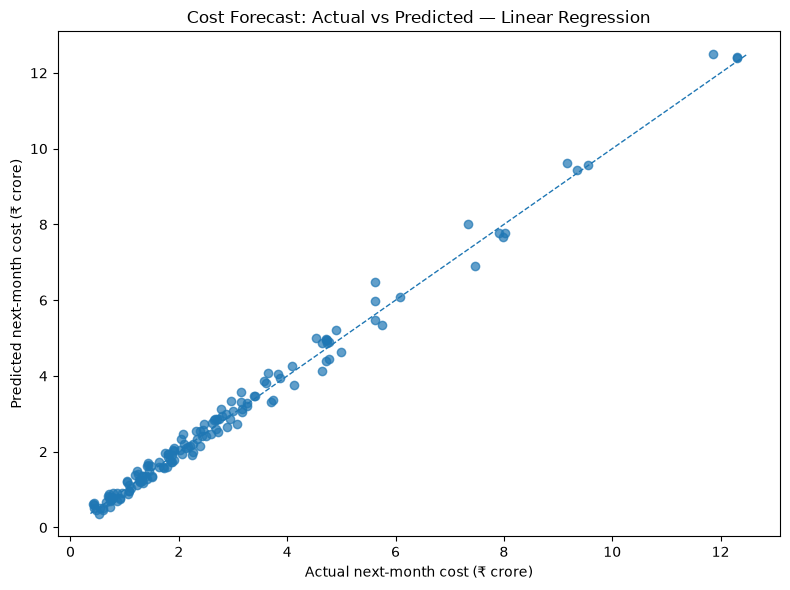

In [30]:
plt.figure(figsize=(8, 6))
plt.scatter(cost_forecast_output["actual_next_month_cost_cr"], cost_forecast_output["predicted_next_month_cost_cr"], alpha=0.7)
min_cost = min(cost_forecast_output["actual_next_month_cost_cr"].min(), cost_forecast_output["predicted_next_month_cost_cr"].min())
max_cost = max(cost_forecast_output["actual_next_month_cost_cr"].max(), cost_forecast_output["predicted_next_month_cost_cr"].max())
plt.plot([min_cost, max_cost], [min_cost, max_cost], linestyle="--", linewidth=1)
plt.xlabel("Actual next-month cost (₹ crore)")
plt.ylabel("Predicted next-month cost (₹ crore)")
plt.title(f"Cost Forecast: Actual vs Predicted — {best_cost_model_name}")
plt.tight_layout()
plt.savefig(VISUALIZATION_DIR / "08_cost_actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()

## 11. Project 3 — Next-Month Progress Forecasting

### Business problem

Forecast the next month's physical progress percentage for each work package. The objective is to provide a forward-looking view of expected progress against the existing baseline.

In [31]:
progress_model_df = df.copy().sort_values(group_columns + ["month"]).reset_index(drop=True)
progress_model_df["next_month_actual_progress_pct"] = (
    progress_model_df.groupby(group_columns)["actual_progress_pct"].shift(-1)
)

for column in ["actual_progress_pct", "planned_progress_pct", "delay_days", "progress_variance_pct", "cost_variance_pct", "SPI", "CPI"]:
    progress_model_df[f"{column}_lag1"] = progress_model_df.groupby(group_columns)[column].shift(1)

progress_model_df = progress_model_df.dropna(subset=["next_month_actual_progress_pct"]).copy()
train_progress = progress_model_df[progress_model_df["month"] < train_cutoff].copy()
test_progress = progress_model_df[progress_model_df["month"] >= train_cutoff].copy()

progress_numeric_features = [
    "contract_value_cr", "budget_cr", "planned_progress_pct", "actual_progress_pct",
    "planned_cost_cr", "actual_cost_cr", "delay_days", "progress_variance_pct",
    "cost_variance_pct", "SPI", "CPI", "month_number",
    "actual_progress_pct_lag1", "planned_progress_pct_lag1", "delay_days_lag1",
    "progress_variance_pct_lag1", "cost_variance_pct_lag1", "SPI_lag1", "CPI_lag1"
]

X_train_progress = train_progress[categorical_features + progress_numeric_features]
y_train_progress = train_progress["next_month_actual_progress_pct"]
X_test_progress = test_progress[categorical_features + progress_numeric_features]
y_test_progress = test_progress["next_month_actual_progress_pct"]

progress_preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, progress_numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

In [32]:
progress_models = {
    "Linear Regression": Pipeline([
        ("preprocessor", progress_preprocessor),
        ("model", LinearRegression())
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", progress_preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=300, max_depth=8, min_samples_leaf=3,
            random_state=42, n_jobs=-1
        ))
    ]),
    "Gradient Boosting": Pipeline([
        ("preprocessor", progress_preprocessor),
        ("model", GradientBoostingRegressor(
            n_estimators=200, learning_rate=0.05, max_depth=3,
            min_samples_leaf=5, random_state=42
        ))
    ])
}

progress_results = []
progress_predictions = {}

for name, model in progress_models.items():
    model.fit(X_train_progress, y_train_progress)
    predictions = np.clip(model.predict(X_test_progress), 0, 100)
    progress_predictions[name] = predictions
    progress_results.append({
        "Model": name,
        "MAE_pct_points": mean_absolute_error(y_test_progress, predictions),
        "RMSE_pct_points": mean_squared_error(y_test_progress, predictions) ** 0.5,
        "R2": r2_score(y_test_progress, predictions)
    })

progress_model_comparison = pd.DataFrame(progress_results).sort_values("MAE_pct_points")
display(progress_model_comparison.round(3))

best_progress_model_name = progress_model_comparison.iloc[0]["Model"]
best_progress_predictions = progress_predictions[best_progress_model_name]

progress_forecast_output = test_progress[["project_name", "contractor", "work_category", "month"]].copy()
progress_forecast_output["actual_next_month_progress_pct"] = y_test_progress.values
progress_forecast_output["predicted_next_month_progress_pct"] = best_progress_predictions
progress_forecast_output["forecast_error_pct_points"] = (
    progress_forecast_output["predicted_next_month_progress_pct"]
    - progress_forecast_output["actual_next_month_progress_pct"]
)

print("Selected progress model:", best_progress_model_name)
display(progress_forecast_output.head(10))

,Model,MAE_pct_points,RMSE_pct_points,R2
1,Random Forest,2.43,3.56,0.79
2,Gradient Boosting,2.63,3.58,0.79
0,Linear Regression,3.59,4.82,0.62


Selected progress model: Random Forest


,project_name,contractor,work_category,month,actual_next_month_progress_pct,predicted_next_month_progress_pct,forecast_error_pct_points
8,Administrative Complex,Contractor B,Earthwork,2025-09-01,91.87,93.05,1.18
9,Administrative Complex,Contractor B,Earthwork,2025-10-01,91.87,92.49,0.62
10,Administrative Complex,Contractor B,Earthwork,2025-11-01,91.87,93.57,1.70
20,Administrative Complex,Contractor B,Electrical,2025-09-01,79.96,76.97,-2.99
21,Administrative Complex,Contractor B,Electrical,2025-10-01,89.74,89.77,0.03
22,Administrative Complex,Contractor B,Electrical,2025-11-01,89.74,90.68,0.94
32,Administrative Complex,Contractor B,Fire Fighting,2025-09-01,77.45,68.13,-9.33
33,Administrative Complex,Contractor B,Fire Fighting,2025-10-01,92.84,91.90,-0.93
34,Administrative Complex,Contractor B,Fire Fighting,2025-11-01,92.84,93.47,0.63
44,Administrative Complex,Contractor B,Flooring,2025-09-01,65.71,66.22,0.51


### 11.1 Forecasting Interpretation

Progress forecasting is a regression problem where the error is expressed in **percentage points of physical progress**. The output can be compared with the baseline plan to identify work packages that may finish the next reporting period below expectation.

As with cost prediction, the current dataset is synthetic and short. The model is therefore a portfolio demonstration rather than a production forecasting system.

### 11.2 Progress Forecast Visualization

This chart compares predicted and actual next-month physical progress. The reference line represents perfect prediction.

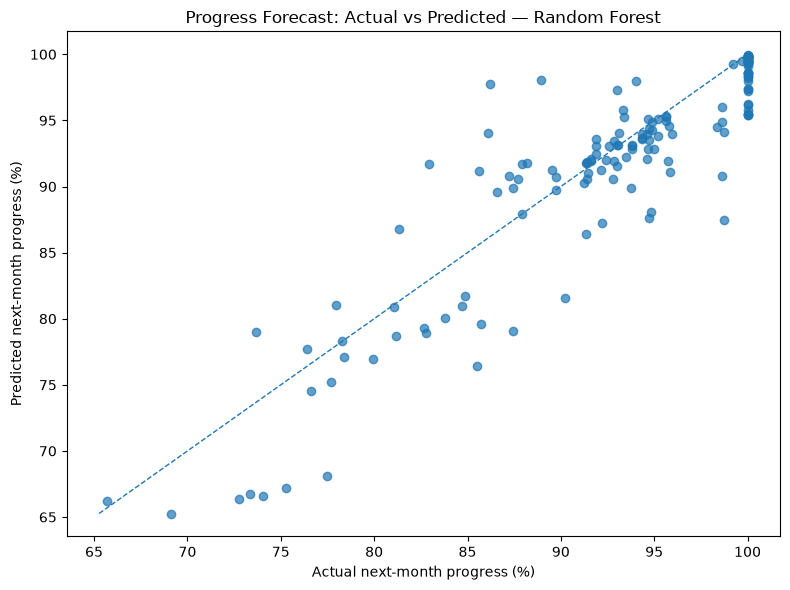

In [33]:
plt.figure(figsize=(8, 6))
plt.scatter(progress_forecast_output["actual_next_month_progress_pct"], progress_forecast_output["predicted_next_month_progress_pct"], alpha=0.7)
min_progress = min(progress_forecast_output["actual_next_month_progress_pct"].min(), progress_forecast_output["predicted_next_month_progress_pct"].min())
max_progress = max(progress_forecast_output["actual_next_month_progress_pct"].max(), progress_forecast_output["predicted_next_month_progress_pct"].max())
plt.plot([min_progress, max_progress], [min_progress, max_progress], linestyle="--", linewidth=1)
plt.xlabel("Actual next-month progress (%)")
plt.ylabel("Predicted next-month progress (%)")
plt.title(f"Progress Forecast: Actual vs Predicted — {best_progress_model_name}")
plt.tight_layout()
plt.savefig(VISUALIZATION_DIR / "09_progress_actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()

## 12. Dashboard-Ready Project Controls Dataset

A practical analytics project should finish with a clean table that a BI tool can consume. The following dataset combines current project KPIs, EVM measures, and predictive outputs at the project-month level.

In [34]:
dashboard_base = (
    df.groupby(["project_name", "contractor", "month"], as_index=False)
      .agg(
          contract_value_cr=("contract_value_cr", "first"),
          planned_progress_pct=("planned_progress_pct", "mean"),
          actual_progress_pct=("actual_progress_pct", "mean"),
          progress_variance_pct=("progress_variance_pct", "mean"),
          planned_cost_cr=("planned_cost_cr", "sum"),
          actual_cost_cr=("actual_cost_cr", "sum"),
          cost_variance_cr=("cost_variance_cr", "sum"),
          cost_variance_pct=("cost_variance_pct", "mean"),
          avg_delay_days=("delay_days", "mean")
      )
)

dashboard = dashboard_base.merge(
    project_month_evm,
    on=["project_name", "contractor", "month"],
    how="left"
)

# Aggregate predictive results to project-month level for dashboard use.
delay_dashboard = (
    test_delay.assign(predicted_high_delay_probability=best_delay_probabilities)
      .groupby(["project_name", "contractor", "month"], as_index=False)
      .agg(predicted_high_delay_probability=("predicted_high_delay_probability", "max"))
)

dashboard = dashboard.merge(
    delay_dashboard,
    on=["project_name", "contractor", "month"],
    how="left"
)

dashboard["delay_risk_flag"] = np.select(
    [dashboard["predicted_high_delay_probability"] >= 0.70, dashboard["predicted_high_delay_probability"] >= 0.50],
    ["High", "Medium"],
    default="Low / Not Scored"
)

dashboard["schedule_flag"] = np.select(
    [dashboard["SPI"] < 0.90, dashboard["SPI"] < 1.00],
    ["Critical", "Behind Plan"],
    default="On / Ahead"
)

dashboard["cost_flag"] = np.select(
    [dashboard["CPI"] < 0.90, dashboard["CPI"] < 1.00],
    ["Critical", "Cost Pressure"],
    default="Efficient / On Plan"
)

display(dashboard.head(12))

,project_name,contractor,month,contract_value_cr,planned_progress_pct,actual_progress_pct,progress_variance_pct,planned_cost_cr,actual_cost_cr,cost_variance_cr,cost_variance_pct,avg_delay_days,PV_cr,AC_cr,EV_cr,SV_cr,CV_cr,SPI,CPI,predicted_high_delay_probability,delay_risk_flag,schedule_flag,cost_flag
0,Administrative Complex,Contractor B,2025-01-01,35.40,4.58,4.12,-0.46,1.73,1.81,0.09,3.20,6.50,1.73,1.81,1.49,-0.23,-0.32,0.86,0.82,NaN,Low / Not Scored,Critical,Critical
1,Administrative Complex,Contractor B,2025-02-01,35.40,9.17,7.49,-1.67,3.45,3.64,0.19,3.53,5.90,3.45,3.64,2.85,-0.60,-0.79,0.83,0.78,NaN,Low / Not Scored,Critical,Critical
2,Administrative Complex,Contractor B,2025-03-01,35.40,15.18,13.42,-1.76,5.68,5.95,0.27,4.64,7.30,5.68,5.95,5.33,-0.35,-0.62,0.94,0.90,NaN,Low / Not Scored,Behind Plan,Critical
3,Administrative Complex,Contractor B,2025-04-01,35.40,23.69,21.62,-2.07,8.89,9.11,0.23,2.44,5.20,8.89,9.11,8.28,-0.60,-0.83,0.93,0.91,NaN,Low / Not Scored,Behind Plan,Cost Pressure
4,Administrative Complex,Contractor B,2025-05-01,35.40,31.37,26.98,-4.39,12.15,12.94,0.79,4.71,5.90,12.15,12.94,10.16,-1.99,-2.78,0.84,0.79,NaN,Low / Not Scored,Critical,Critical
5,Administrative Complex,Contractor B,2025-06-01,35.40,40.71,37.31,-3.41,15.71,16.19,0.47,2.04,5.80,15.71,16.19,14.65,-1.06,-1.54,0.93,0.91,NaN,Low / Not Scored,Behind Plan,Cost Pressure
6,Administrative Complex,Contractor B,2025-07-01,35.40,54.06,49.57,-4.49,20.54,21.61,1.07,3.08,6.00,20.54,21.61,19.02,-1.52,-2.59,0.93,0.88,NaN,Low / Not Scored,Behind Plan,Critical
7,Administrative Complex,Contractor B,2025-08-01,35.40,67.40,60.57,-6.83,25.38,26.55,1.17,2.73,5.50,25.38,26.55,22.95,-2.43,-3.60,0.90,0.86,NaN,Low / Not Scored,Behind Plan,Critical
8,Administrative Complex,Contractor B,2025-09-01,35.40,79.50,70.85,-8.65,29.10,30.16,1.05,2.59,5.30,29.10,30.16,25.98,-3.12,-4.17,0.89,0.86,0.56,Medium,Critical,Critical
9,Administrative Complex,Contractor B,2025-10-01,35.40,90.17,80.48,-9.69,32.33,33.59,1.26,2.62,8.40,32.33,33.59,28.98,-3.34,-4.60,0.90,0.86,0.60,Medium,Critical,Critical


In [35]:
dashboard.to_csv(OUTPUT_DIR / "project_controls_dashboard.csv", index=False)
project_summary.to_csv(OUTPUT_DIR / "project_summary.csv", index=False)
category_summary.to_csv(OUTPUT_DIR / "category_summary.csv", index=False)
evm_project_summary.to_csv(OUTPUT_DIR / "evm_project_summary.csv", index=False)
cost_forecast_output.to_csv(OUTPUT_DIR / "cost_forecast_output.csv", index=False)
progress_forecast_output.to_csv(OUTPUT_DIR / "progress_forecast_output.csv", index=False)

print("Dashboard and analysis outputs exported to:", OUTPUT_DIR)

Dashboard and analysis outputs exported to: /Users/ananthrb/Desktop/construction-project-analytics/outputs


### 12.1 Executive Dashboard Visualizations

These charts are the Python prototype for the Power BI executive dashboard. They focus on schedule health, cost health, and early-warning risk.

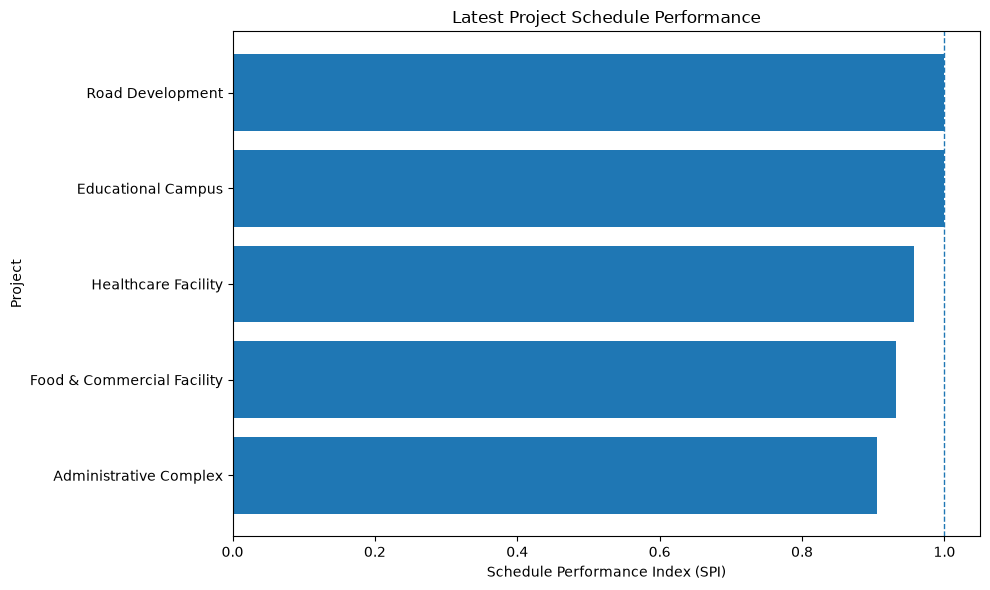

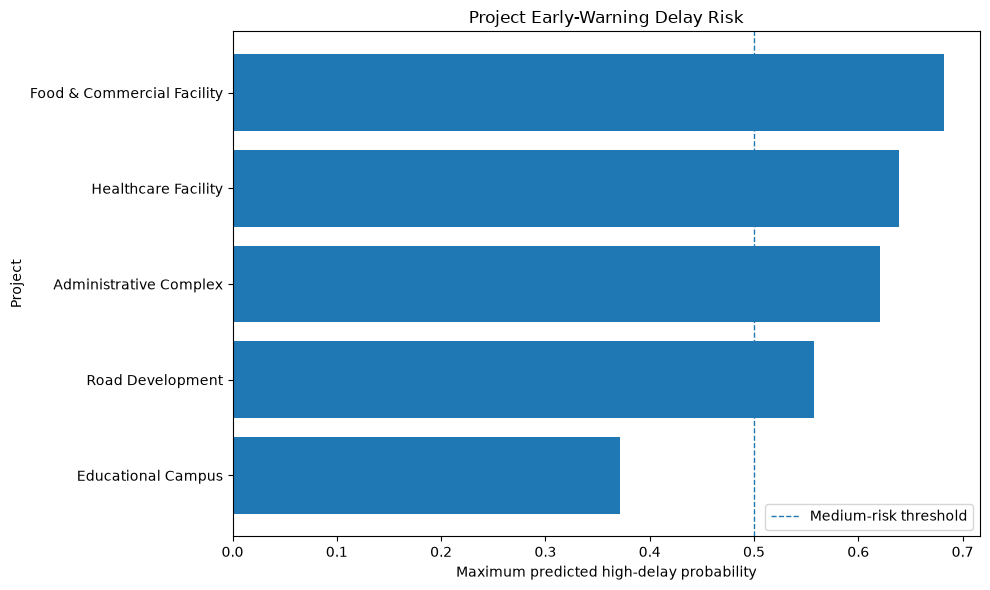

In [36]:
latest_dashboard = dashboard.sort_values("month").groupby("project_name", as_index=False).tail(1).copy()

plt.figure(figsize=(10, 6))
plt.barh(latest_dashboard.sort_values("SPI")["project_name"], latest_dashboard.sort_values("SPI")["SPI"])
plt.axvline(1.0, linestyle="--", linewidth=1)
plt.xlabel("Schedule Performance Index (SPI)")
plt.ylabel("Project")
plt.title("Latest Project Schedule Performance")
plt.tight_layout()
plt.savefig(VISUALIZATION_DIR / "10_latest_project_spi.png", dpi=300, bbox_inches="tight")
plt.show()

scored_dashboard = dashboard.dropna(subset=["predicted_high_delay_probability"]).copy()
if not scored_dashboard.empty:
    risk_plot = (
        scored_dashboard.groupby("project_name", as_index=False)["predicted_high_delay_probability"]
        .max().sort_values("predicted_high_delay_probability")
    )
    plt.figure(figsize=(10, 6))
    plt.barh(risk_plot["project_name"], risk_plot["predicted_high_delay_probability"])
    plt.axvline(0.50, linestyle="--", linewidth=1, label="Medium-risk threshold")
    plt.xlabel("Maximum predicted high-delay probability")
    plt.ylabel("Project")
    plt.title("Project Early-Warning Delay Risk")
    plt.legend()
    plt.tight_layout()
    plt.savefig(VISUALIZATION_DIR / "11_project_delay_risk.png", dpi=300, bbox_inches="tight")
    plt.show()

## 13. Project 4 — AI-Ready Project Intelligence Prototype

This section demonstrates how analytics outputs can be converted into a structured decision-support layer.

It is deliberately labelled **AI-ready** rather than claiming a production Generative AI system. A real RAG/GenAI implementation would require a document corpus, embeddings/vector search, retrieval evaluation, access controls, and an LLM service.

In [37]:
intelligence = dashboard.copy()

def build_recommendation(row):
    actions = []
    if row["SPI"] < 0.90:
        actions.append("Review schedule recovery plan")
    elif row["SPI"] < 1.00:
        actions.append("Monitor schedule variance")

    if row["CPI"] < 0.90:
        actions.append("Investigate cost overrun drivers")
    elif row["CPI"] < 1.00:
        actions.append("Monitor cost efficiency")

    if row["delay_risk_flag"] == "High":
        actions.append("Review high-delay early-warning indicators")

    if not actions:
        actions.append("Continue routine project controls monitoring")

    return "; ".join(actions)

intelligence["recommended_action"] = intelligence.apply(build_recommendation, axis=1)

intelligence_view = intelligence[[
    "project_name", "contractor", "month", "SPI", "CPI",
    "predicted_high_delay_probability", "delay_risk_flag",
    "schedule_flag", "cost_flag", "recommended_action"
]].sort_values(["month", "project_name"])

display(intelligence_view.tail(15))
intelligence_view.to_csv(OUTPUT_DIR / "project_intelligence_output.csv", index=False)

,project_name,contractor,month,SPI,CPI,predicted_high_delay_probability,delay_risk_flag,schedule_flag,cost_flag,recommended_action
9,Administrative Complex,Contractor B,2025-10-01,0.90,0.86,0.60,Medium,Critical,Critical,Review schedule recovery plan; Investigate cos...
21,Educational Campus,Contractor C,2025-10-01,1.04,1.02,0.37,Low / Not Scored,On / Ahead,Efficient / On Plan,Continue routine project controls monitoring
33,Food & Commercial Facility,Contractor A,2025-10-01,0.92,0.84,0.61,Medium,Behind Plan,Critical,Monitor schedule variance; Investigate cost ov...
45,Healthcare Facility,Contractor A,2025-10-01,0.95,0.88,0.64,Medium,Behind Plan,Critical,Monitor schedule variance; Investigate cost ov...
57,Road Development,Contractor B,2025-10-01,1.00,0.98,0.52,Medium,Behind Plan,Cost Pressure,Monitor schedule variance; Monitor cost effici...
10,Administrative Complex,Contractor B,2025-11-01,0.90,0.86,0.62,Medium,Behind Plan,Critical,Monitor schedule variance; Investigate cost ov...
22,Educational Campus,Contractor C,2025-11-01,1.01,0.99,0.28,Low / Not Scored,On / Ahead,Cost Pressure,Monitor cost efficiency
34,Food & Commercial Facility,Contractor A,2025-11-01,0.92,0.84,0.68,Medium,Behind Plan,Critical,Monitor schedule variance; Investigate cost ov...
46,Healthcare Facility,Contractor A,2025-11-01,0.95,0.88,0.60,Medium,Behind Plan,Critical,Monitor schedule variance; Investigate cost ov...
58,Road Development,Contractor B,2025-11-01,1.00,0.98,0.48,Low / Not Scored,On / Ahead,Cost Pressure,Monitor cost efficiency


### How this becomes a RAG / GenAI system

A production architecture could connect this structured analytics layer with project documents such as:

- approved drawings and revisions,
- contracts and BOQs,
- RFIs and technical queries,
- meeting minutes,
- site reports,
- material approvals,
- payment and billing records.

A retrieval layer would fetch relevant project evidence, while an LLM could generate a concise explanation of **why a project is flagged and which documents support the recommendation**. The notebook stops at the validated analytics layer rather than fabricating a GenAI implementation.

### Visualization Inventory

The notebook now produces a focused set of presentation-ready charts covering project performance, contractor performance, work-category delay, statistical relationships, EVM trends, model evaluation, forecasting accuracy, and dashboard risk indicators. Each visualization is tied to a defined business question rather than included only for decoration.

## 14. Final Business Findings Framework

The final conclusions should be driven by the executed outputs rather than hard-coded statements. The following cells identify the worst-performing project, work category, and contractor from the calculated metrics.

In [38]:
worst_project = project_summary.loc[project_summary["avg_progress_variance_pct"].idxmin()]
worst_category = category_summary.loc[category_summary["avg_delay_days"].idxmax()]
worst_contractor = contractor_summary.loc[contractor_summary["avg_progress_variance_pct"].idxmin()]

print("Worst average project progress variance:")
print(worst_project[["project_name", "avg_progress_variance_pct", "avg_delay_days"]].to_dict())

print("\nHighest average work-category delay:")
print(worst_category[["work_category", "avg_delay_days", "avg_progress_variance_pct"]].to_dict())

print("\nLowest contractor progress variance:")
print(worst_contractor[["contractor", "avg_progress_variance_pct", "avg_delay_days"]].to_dict())

print("\nBest delay-risk model by ROC-AUC:", best_delay_model_name)
print("Best cost model by MAE:", best_cost_model_name)
print("Best progress model by MAE:", best_progress_model_name)

Worst average project progress variance:
{'project_name': 'Administrative Complex', 'avg_progress_variance_pct': -5.254425777734044, 'avg_delay_days': 6.175}

Highest average work-category delay:
{'work_category': 'RCC', 'avg_delay_days': 5.266666666666667, 'avg_progress_variance_pct': -2.699156652887197}

Lowest contractor progress variance:
{'contractor': 'Contractor A', 'avg_progress_variance_pct': -3.119297418669492, 'avg_delay_days': 5.533333333333333}

Best delay-risk model by ROC-AUC: Random Forest
Best cost model by MAE: Linear Regression
Best progress model by MAE: Random Forest


## 15. Limitations & Production Considerations

1. **Synthetic data:** Results demonstrate methodology and cannot be treated as evidence about real contractors or projects.
2. **Short history:** Twelve months is insufficient for robust production forecasting across construction cycles.
3. **Repeated observations:** Project/work-package records are not independent, so statistical inference should be treated cautiously.
4. **Target definition:** The 75th-percentile delay threshold is a modelling convention, not an industry-standard contractual threshold.
5. **External drivers:** Weather, procurement lead times, design changes, labour availability, approvals, and site constraints are not explicitly represented.
6. **Model validation:** Production models should use multiple projects and rolling time-based back-testing.
7. **BI layer:** The notebook exports dashboard-ready data; a `.pbix` or Tableau workbook is a separate visualization deliverable.
8. **GenAI:** The intelligence section is an AI-ready prototype, not a deployed RAG/LLM application.

## 16. Portfolio Summary

This project demonstrates an end-to-end data-science workflow for construction project controls:

**Python → Data Analytics → Statistical Analysis → SQL → EVM → Feature Engineering → Classification → Regression → Forecasting → Power BI-ready outputs → AI-ready project intelligence**

The strongest portfolio narrative is not that machine learning alone solves construction problems. It is that **domain knowledge is translated into measurable variables, validated analytics, predictive models, and decision-support outputs**.

In [39]:
print("=" * 70)
print("FINAL NOTEBOOK VALIDATION")
print("=" * 70)
print("Base dataset shape:", df.shape)
print("Project-month EVM rows:", len(project_month_evm))
print("Delay model train/test:", len(train_delay), "/", len(test_delay))
print("Cost model train/test:", len(train_cost), "/", len(test_cost))
print("Progress model train/test:", len(train_progress), "/", len(test_progress))
print("Output files created:", len(list(OUTPUT_DIR.glob("*.csv"))))
print("Notebook pipeline completed successfully.")

FINAL NOTEBOOK VALIDATION
Base dataset shape: (600, 23)
Project-month EVM rows: 60
Delay model train/test: 400 / 150
Cost model train/test: 400 / 150
Progress model train/test: 400 / 150
Output files created: 7
Notebook pipeline completed successfully.
